# Phase 2 — Technical Application (Baseline Implementation)
## Diabetes Prediction Using Machine Learning and Explainable AI Techniques

**Student:** KSMM Samarakoon  
**Student ID:** KIC-BSCCSAI-251P-038  
**Research paper:** Tasin, I., Nabil, T. U., Islam, S., & Khan, R. (2023). *Diabetes prediction using machine learning and explainable AI techniques*. Healthcare Technology Letters, 10(1–2), 1–10. https://doi.org/10.1049/htl2.12039

### Aim
Implement and evaluate two conventional baseline classifiers on the publicly available Pima Indians Diabetes Database. Compare the measured baseline results with the headline results reported by the paper, while clearly noting that the paper also used a separate RTML dataset and a more advanced pipeline.

### Research question
How well do simple Logistic Regression and Random Forest baselines classify diabetes outcomes on the Pima dataset when preprocessing is fitted only on the training data?

### Reproducibility
The notebook uses a fixed random seed (`42`), a stratified 80:20 train/test split, and scikit-learn pipelines. Run all cells from top to bottom. The dataset is downloaded from a public raw CSV URL; internet access is required unless a local copy is supplied.

## 1. Install and import libraries
Required packages: `pandas`, `numpy`, `matplotlib`, and `scikit-learn`. If any package is missing, install it in the VS Code terminal using `python -m pip install pandas numpy matplotlib scikit-learn`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset
The original Pima dataset mirror contains 768 records and has no header row, so the feature names are assigned explicitly. If the online download fails, download the CSV from the link in the report and update `LOCAL_CSV_PATH` to its location.

In [2]:
columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]
DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
LOCAL_CSV_PATH = None  # Example: r"C:\Users\YourName\Downloads\pima-indians-diabetes.data.csv"

try:
    if LOCAL_CSV_PATH:
        df = pd.read_csv(LOCAL_CSV_PATH, header=None, names=columns)
    else:
        df = pd.read_csv(DATA_URL, header=None, names=columns)
except Exception as exc:
    raise RuntimeError(
        "Could not download the dataset. Download the CSV manually, set LOCAL_CSV_PATH, and rerun."
    ) from exc

print("Dataset shape:", df.shape)
display(df.head())
display(df.describe().T)

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


## 3. Inspect the target and invalid zero values
The Phase 1 audit notes that zero is a valid value for `Pregnancies`, but generally an impossible physiological measurement for `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI`. These zeros are treated as missing values for modelling. We will fit the imputer within each model pipeline so that imputation statistics are learned from training data only.

In [3]:
print("Target distribution (count):")
display(df["Outcome"].value_counts().sort_index().rename(index={0: "Non-diabetic (0)", 1: "Diabetic (1)"}).to_frame("count"))

invalid_zero_features = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_summary = pd.DataFrame({
    "zero_count": [(df[c] == 0).sum() for c in invalid_zero_features],
    "zero_percent": [100 * (df[c] == 0).mean() for c in invalid_zero_features]
}, index=invalid_zero_features)
display(zero_summary.round(2))

df_model = df.copy()
df_model[invalid_zero_features] = df_model[invalid_zero_features].replace(0, np.nan)

print("Missing values after converting physiologically invalid zeros:")
display(df_model.isna().sum().to_frame("missing_count"))

Target distribution (count):


,count
Outcome,
Non-diabetic (0),500
Diabetic (1),268


,zero_count,zero_percent
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


Missing values after converting physiologically invalid zeros:


,missing_count
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


## 4. Prepare training and test sets
The target is `Outcome` (1 = diabetes, 0 = no diabetes). The eight clinical and demographic columns are the predictors. A stratified split preserves approximately the same target-class proportions in the training and test partitions.

In [4]:
X = df_model.drop(columns="Outcome")
y = df_model["Outcome"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename(index={0: "0 = non-diabetic", 1: "1 = diabetic"}).to_frame("proportion"))
print("Test target proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename(index={0: "0 = non-diabetic", 1: "1 = diabetic"}).to_frame("proportion"))

Training rows: 614
Test rows: 154

Training target proportions:


,proportion
Outcome,
0 = non-diabetic,0.651466
1 = diabetic,0.348534


Test target proportions:


,proportion
Outcome,
0 = non-diabetic,0.649351
1 = diabetic,0.350649


## 5. Define baseline models
Two common classifiers are evaluated:

1. **Logistic Regression:** a linear probabilistic baseline. Median imputation and standardisation are fitted within the pipeline.
2. **Random Forest:** a nonlinear ensemble of decision trees. Median imputation is fitted within the pipeline; scaling is not required for tree-based models.

No oversampling is applied. This is deliberate: the Phase 1 audit identifies the need to compare oversampling against a no-resampling baseline rather than assuming SMOTE or ADASYN is necessary.

In [5]:
models = {
    "Logistic Regression": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, class_weight=None, random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            class_weight=None,
            min_samples_leaf=2
        ))
    ])
}
print("Baseline pipelines created.")

Baseline pipelines created.


## 6. Train and evaluate the models
The untouched test partition is used only for final evaluation. We report accuracy, precision, recall, F1, and ROC-AUC, together with confusion matrices and classification reports. Because diabetes screening may place greater importance on identifying positive cases, recall should be interpreted alongside precision and specificity rather than using accuracy alone.

In [6]:
results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model

    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall (Sensitivity)": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score)
    })

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)
    print(classification_report(y_test, y_pred, target_names=["Non-diabetic", "Diabetic"], zero_division=0))
    print("Confusion matrix [ [TN, FP], [FN, TP] ]:")
    print(confusion_matrix(y_test, y_pred))

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))


Logistic Regression
              precision    recall  f1-score   support

Non-diabetic       0.76      0.81      0.79       100
    Diabetic       0.60      0.54      0.57        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.68       154
weighted avg       0.71      0.71      0.71       154

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[81 19]
 [25 29]]

Random Forest
              precision    recall  f1-score   support

Non-diabetic       0.78      0.86      0.82       100
    Diabetic       0.68      0.56      0.61        54

    accuracy                           0.75       154
   macro avg       0.73      0.71      0.72       154
weighted avg       0.75      0.75      0.75       154

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[86 14]
 [24 30]]


,Accuracy,Precision,Recall (Sensitivity),F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7143,0.6042,0.5370,0.5686,0.8178
Random Forest,0.7532,0.6818,0.5556,0.6122,0.8113


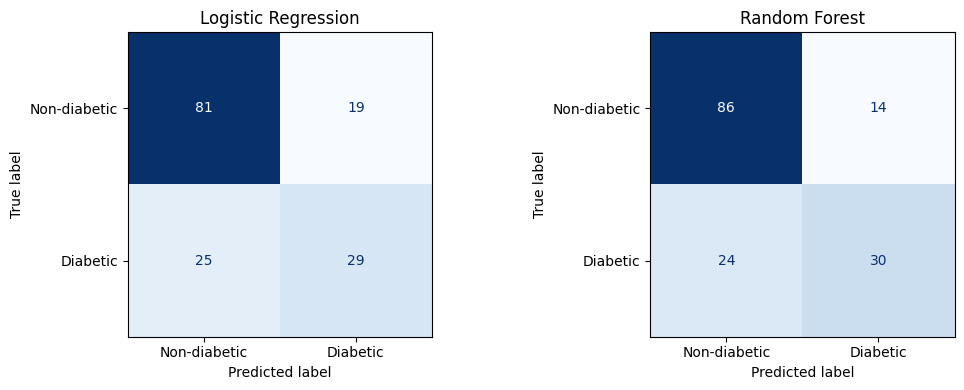

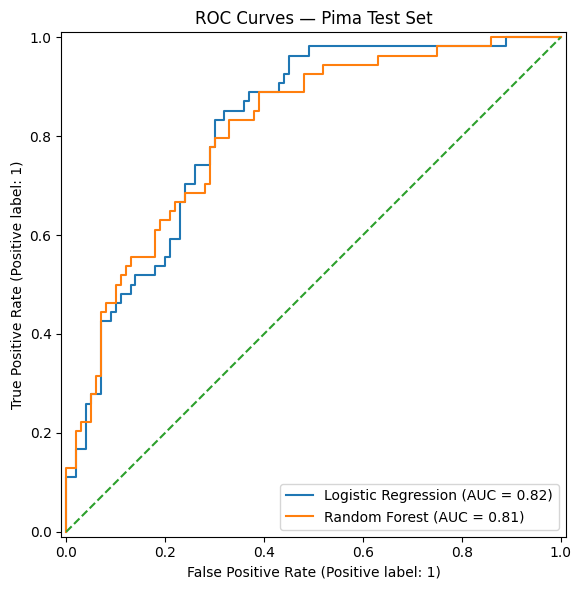

In [7]:
# Confusion matrices
fig, axes = plt.subplots(1, len(fitted_models), figsize=(11, 4))
if len(fitted_models) == 1:
    axes = [axes]
for ax, (name, model) in zip(axes, fitted_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        display_labels=["Non-diabetic", "Diabetic"],
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

# ROC curves
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in fitted_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
ax.set_title("ROC Curves — Pima Test Set")
plt.tight_layout()
plt.show()

## 7. Compare the baseline with the published paper
The paper reports XGBoost + ADASYN with 81% accuracy, F1 = 0.81, and ROC-AUC = 0.84 in its headline results. Its data included 768 Pima records and 203 RTML records. The current baseline uses only the Pima dataset and a fixed 80:20 split. Therefore, the table below is contextual rather than a controlled head-to-head comparison.

The paper also contains a reported accuracy inconsistency (81% in the abstract/results versus 88.5% in a comparison table), identified in the Phase 1 audit. The headline 81% result is used here to avoid silently mixing inconsistent values.

In [8]:
paper_reference = pd.DataFrame([
    {"Approach": "Paper: XGBoost + ADASYN (headline result)", "Accuracy": 0.81, "F1-score": 0.81, "ROC-AUC": 0.84},
    {"Approach": "Paper: XGBoost + SMOTE (reported results table)", "Accuracy": 0.78, "F1-score": 0.78, "ROC-AUC": 0.84},
])
display(paper_reference.set_index("Approach"))

print("Your measured baseline results:")
display(results_df[["Accuracy", "F1-score", "ROC-AUC"]].round(4))

print(
    "\nInterpretation caution: differences may reflect dataset composition, split, "
    "preprocessing, and evaluation design—not only the classifier."
)

,Accuracy,F1-score,ROC-AUC
Approach,,,
Paper: XGBoost + ADASYN (headline result),0.81,0.81,0.84
Paper: XGBoost + SMOTE (reported results table),0.78,0.78,0.84


Your measured baseline results:


,Accuracy,F1-score,ROC-AUC
Model,,,
Logistic Regression,0.7143,0.5686,0.8178
Random Forest,0.7532,0.6122,0.8113



Interpretation caution: differences may reflect dataset composition, split, preprocessing, and evaluation design—not only the classifier.


## 8. Save results for the Phase 2 report
This cell saves the measured metrics and invalid-zero summary so that the report can use actual outputs from your execution. Do not insert invented values into the report; run the notebook and use the generated CSV files.

In [9]:
metrics_path = "phase2_baseline_metrics.csv"
zero_path = "phase2_invalid_zero_summary.csv"
results_df.to_csv(metrics_path)
zero_summary.to_csv(zero_path)
print(f"Saved: {metrics_path}")
print(f"Saved: {zero_path}")
display(results_df.round(4))

Saved: phase2_baseline_metrics.csv
Saved: phase2_invalid_zero_summary.csv


,Accuracy,Precision,Recall (Sensitivity),F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7143,0.6042,0.5370,0.5686,0.8178
Random Forest,0.7532,0.6818,0.5556,0.6122,0.8113


## 9. Discussion and limitations
Use the measured output above to complete your discussion:

- Identify which baseline achieved the highest F1 and ROC-AUC.
- Compare its measured metrics with the paper's headline metrics (accuracy 0.81, F1 0.81, AUC 0.84).
- Explain why the comparison is not like-for-like: the paper merges Pima with RTML and uses feature selection, oversampling, and XGBoost, whereas this notebook uses Pima alone and two simpler baselines.
- Discuss class imbalance, the invalid-zero treatment, and why fitting preprocessing inside the pipeline helps reduce leakage.
- State that this is an educational baseline on a historical dataset, not a clinically validated diagnostic system.

### Conclusion template
After executing the notebook, complete this paragraph with your measured values:

“On the Pima test set, **[model name]** achieved accuracy **[value]**, F1-score **[value]**, and ROC-AUC **[value]**. Compared with the paper’s headline XGBoost + ADASYN results (accuracy 0.81, F1 0.81, AUC 0.84), the baseline **[brief comparison based on the results]**. This comparison should be interpreted cautiously because the paper used a merged Pima–RTML dataset and a different experimental pipeline.”

### References
Tasin, I., Nabil, T. U., Islam, S., & Khan, R. (2023). Diabetes prediction using machine learning and explainable AI techniques. *Healthcare Technology Letters, 10*(1–2), 1–10. https://doi.org/10.1049/htl2.12039

Smith, J. W., Everhart, J. E., Dickson, W. C., Knowler, W. C., & Johannes, R. S. (1988). Using the ADAP learning algorithm to forecast the onset of diabetes mellitus. *Proceedings of the Annual Symposium on Computer Applications in Medical Care*, 261–265.

Dataset mirror: https://github.com/jbrownlee/Datasets/blob/master/pima-indians-diabetes.data.csv